
SETUP & IMPORTS

 SETUP & IMPORTS

In [1]:
import sys, os
sys.path.insert(0, '../src')

import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from preprocessing import DataPreprocessor
from models import ModelTrainer
from evaluation import ModelEvaluator
from utils import analyze_class_distribution, analyze_features, get_system_info

plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

print("✓ All imports successful")

✓ All imports successful


In [2]:
get_system_info()


🖥️  INFORMATIONS SYSTÈME
Python:      3.11.9
Platform:    Windows
Scikit-learn: 1.3.0



 LOAD & EXPLORE

In [3]:
preprocessor = DataPreprocessor()
df = preprocessor.load_data('../data/ton_iot_sample.csv')
print(f"✓ Dataset: {df.shape}")

✓ Données chargées: (10000, 26)
✓ Dataset: (10000, 26)


In [4]:
print(f"Info:\n Shape: {df.shape}\n Columns: {len(df.columns)}\n Missing: {df.isnull().sum().sum()}")

Info:
 Shape: (10000, 26)
 Columns: 26
 Missing: 0


In [5]:
target_col = 'attack'
print(f"Target: {target_col}")
print(f"Classes: {df[target_col].value_counts().to_dict()}")

Target: attack
Classes: {1: 5000, 0: 5000}


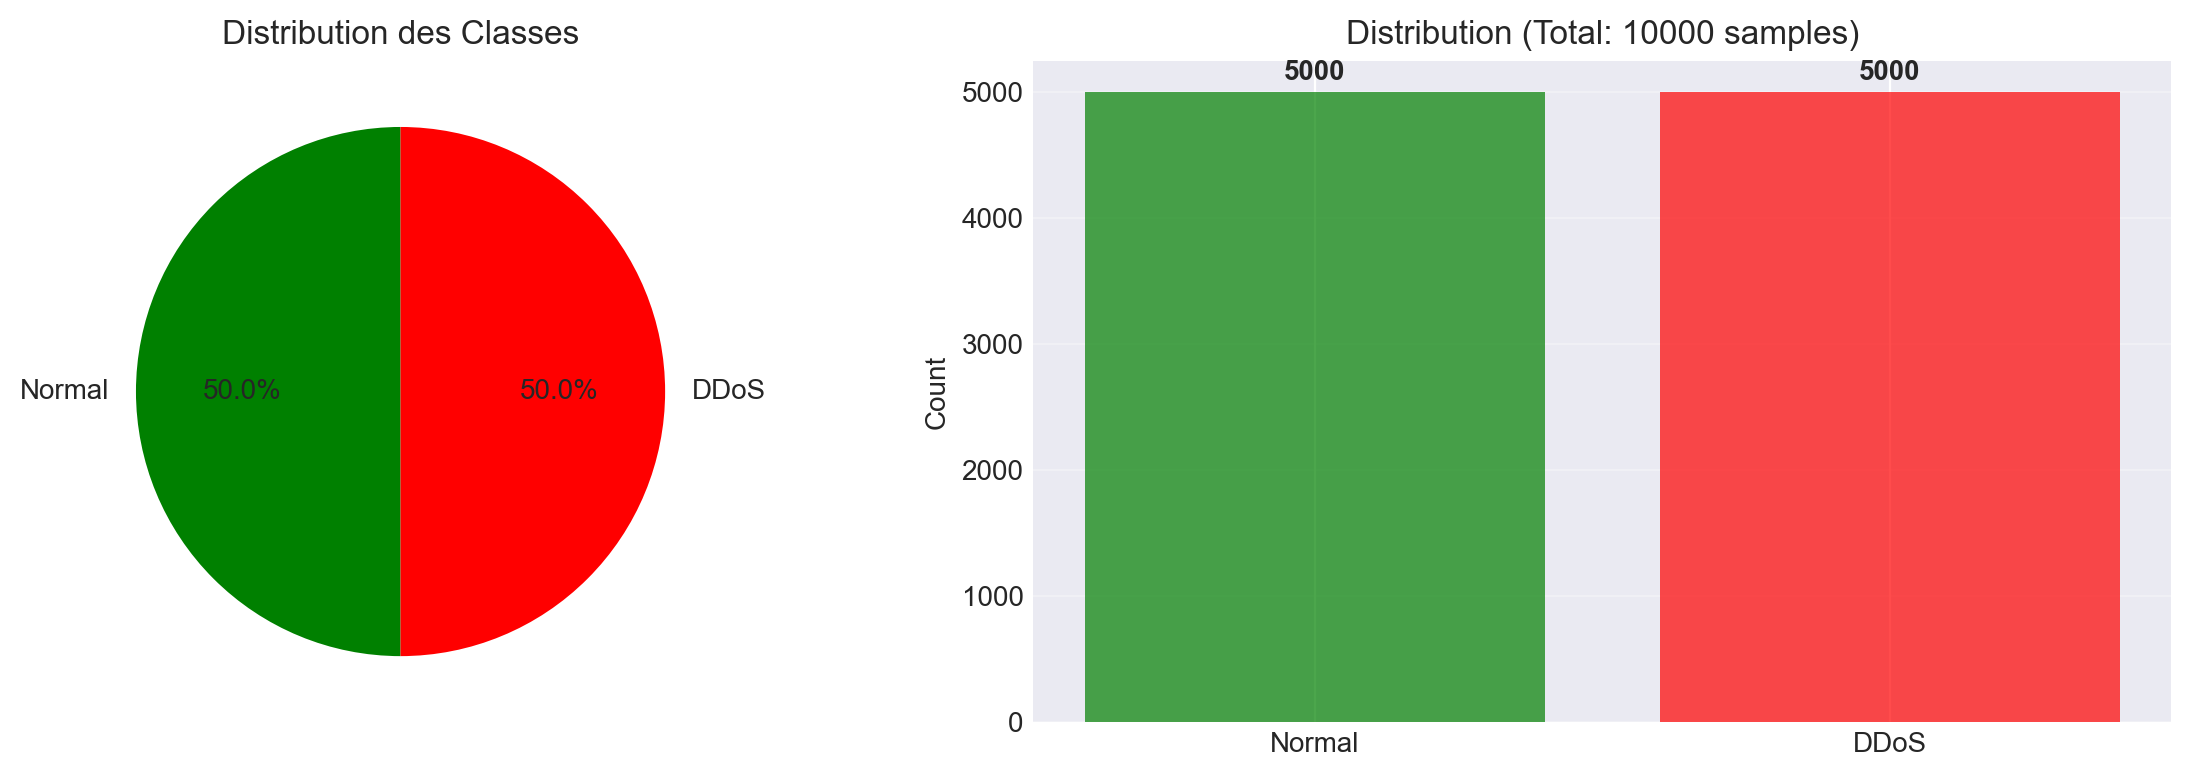

In [6]:
analyze_class_distribution(df[target_col].values)


📈 ANALYSE DES FEATURES

🔗 Top 10 Features (Corrélation avec target):
feature_2     0.906769
feature_4     0.906303
feature_10    0.906194
feature_19    0.905884
feature_17    0.905092
feature_21    0.904937
feature_11    0.904277
feature_8     0.904252
feature_18    0.904220
feature_16    0.904190
dtype: float64


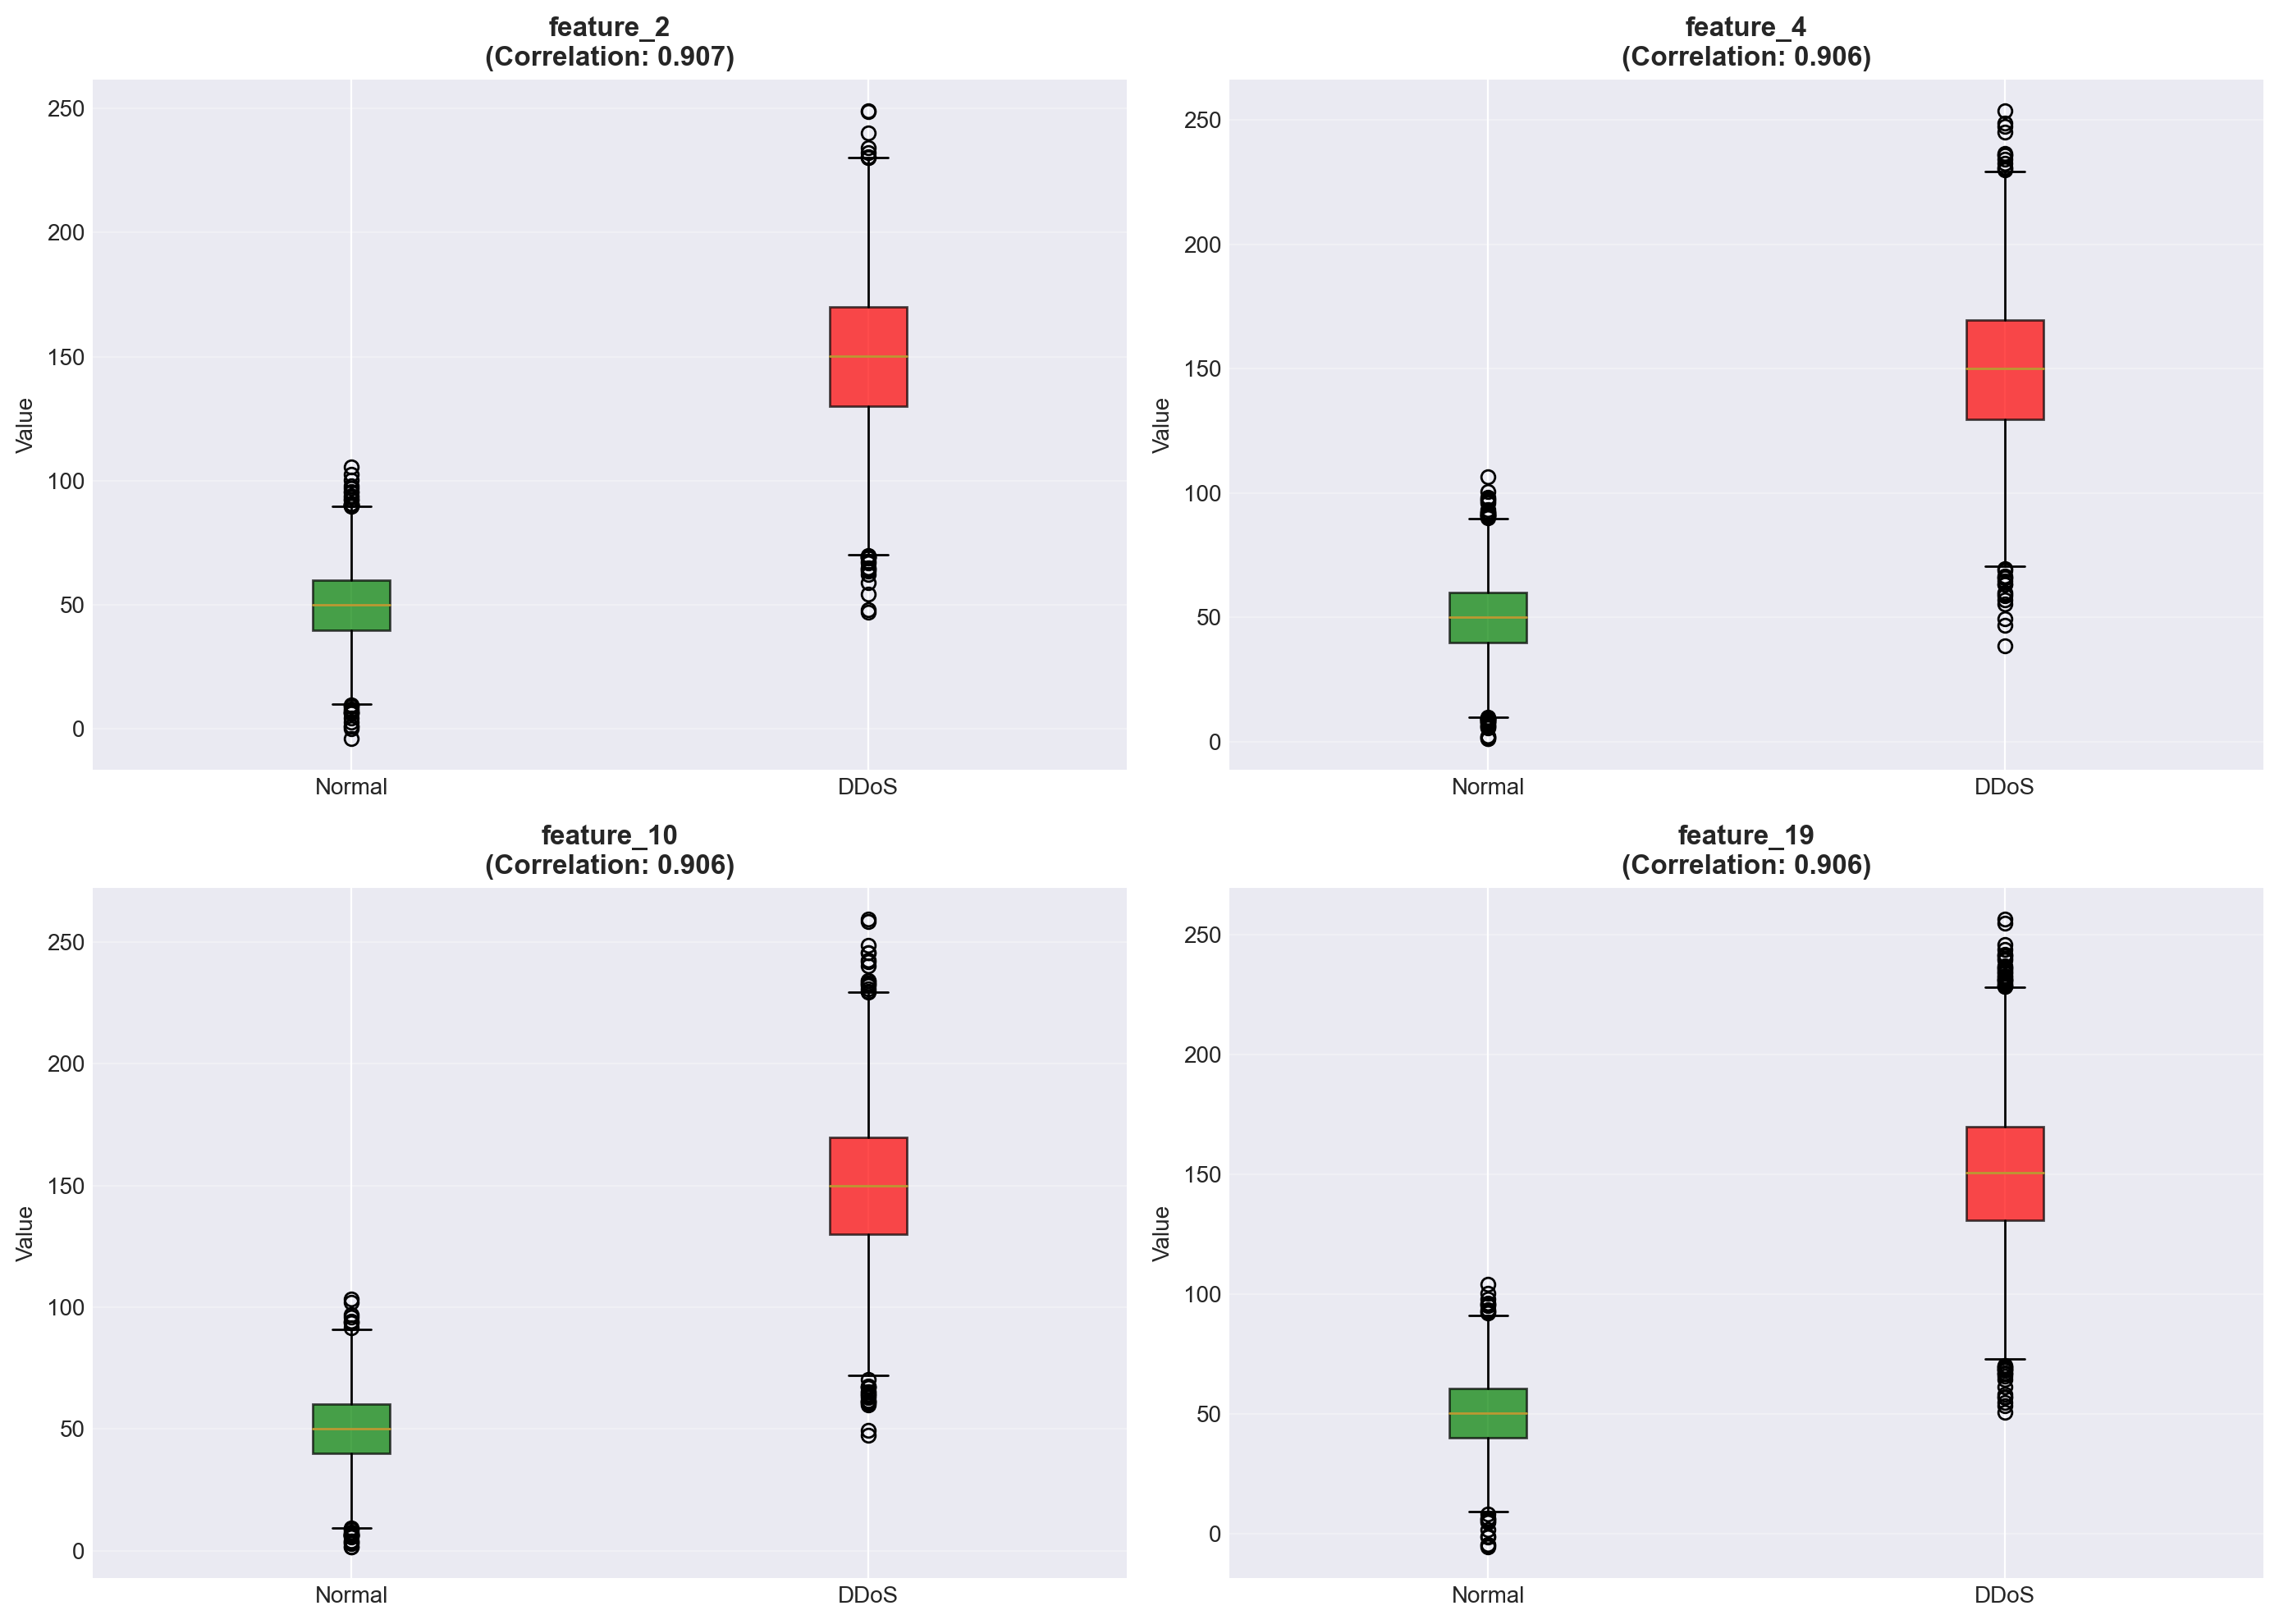

feature_2     0.906769
feature_4     0.906303
feature_10    0.906194
feature_19    0.905884
feature_17    0.905092
feature_21    0.904937
feature_11    0.904277
feature_8     0.904252
feature_18    0.904220
feature_16    0.904190
feature_12    0.903827
feature_13    0.903743
feature_6     0.903727
feature_0     0.903654
feature_7     0.903502
feature_24    0.903344
feature_23    0.903234
feature_14    0.902463
feature_5     0.902218
feature_1     0.902095
feature_9     0.901838
feature_3     0.901305
feature_15    0.900885
feature_22    0.899981
feature_20    0.899491
dtype: float64

In [7]:
analyze_features(df, target_col='attack', top_n=10)


 PREPROCESSING

In [8]:
X_train, X_val, X_test, y_train, y_val, y_test = preprocessor.preprocess(
    df, target_col=target_col, categorical_cols=None
)
print(f"\n✓ Preprocessing done")


🔧 PRÉTRAITEMENT
✓ Pas de valeurs manquantes
✓ Pas de colonnes catégorielles

⚠️  Distribution des classes:
  Classe 0: 5000 (50.0%)
  Classe 1: 5000 (50.0%)
✓ Split stratifié:
  Train: 7000 samples
  Val:   1500 samples
  Test:  1500 samples
✓ Données standardisées (z-score)

✓ Preprocessing done


In [9]:
print(f"Split: Train {X_train.shape[0]} | Val {X_val.shape[0]} | Test {X_test.shape[0]}")

Split: Train 7000 | Val 1500 | Test 1500


TRAINING

In [10]:
trainer = ModelTrainer()
print("🚀 TRAINING...\n")

🚀 TRAINING...



In [11]:
model_knn = trainer.train_knn(X_train, y_train, X_val, y_val, k_values=[3, 5, 7, 9, 11, 15, 21])


🟦 K-NEAREST NEIGHBORS (KNN)
Test k values: [3, 5, 7, 9, 11, 15, 21]
  k= 3 -> Val Accuracy: 1.0000
  k= 5 -> Val Accuracy: 1.0000
  k= 7 -> Val Accuracy: 1.0000
  k= 9 -> Val Accuracy: 1.0000
  k=11 -> Val Accuracy: 1.0000
  k=15 -> Val Accuracy: 1.0000
  k=21 -> Val Accuracy: 1.0000

✓ Meilleur k: 3
✓ Temps d'entraînement: 0.0030s


In [12]:
model_dt = trainer.train_decision_tree(X_train, y_train, X_val, y_val)


🟩 DECISION TREE
✓ Meilleurs paramètres: {'max_depth': 5, 'min_samples_split': 2, 'min_samples_leaf': 1}
✓ Temps d'entraînement: 0.2121s


In [13]:
model_svm = trainer.train_svm(X_train, y_train, X_val, y_val)


🟪 SUPPORT VECTOR MACHINE (SVM)
Test kernels: ['linear', 'rbf', 'poly']
Test C values: [0.1, 1, 10, 100]
  kernel=linear, C=   0.1 -> Val Accuracy: 1.0000
  kernel=linear, C=   1.0 -> Val Accuracy: 1.0000
  kernel=linear, C=  10.0 -> Val Accuracy: 1.0000
  kernel=linear, C= 100.0 -> Val Accuracy: 1.0000
  kernel=rbf  , C=   0.1 -> Val Accuracy: 1.0000
  kernel=rbf  , C=   1.0 -> Val Accuracy: 1.0000
  kernel=rbf  , C=  10.0 -> Val Accuracy: 1.0000
  kernel=rbf  , C= 100.0 -> Val Accuracy: 1.0000
  kernel=poly , C=   0.1 -> Val Accuracy: 1.0000
  kernel=poly , C=   1.0 -> Val Accuracy: 1.0000
  kernel=poly , C=  10.0 -> Val Accuracy: 1.0000
  kernel=poly , C= 100.0 -> Val Accuracy: 1.0000

✓ Meilleur kernel: linear, C: 0.1
✓ Temps d'entraînement: 0.0704s


In [14]:
summary = trainer.get_summary()
print(f"\n{'='*50}\nTRAINING SUMMARY\n{'='*50}")
print(f"\nTimes (seconds):")
for m, t in summary['Training Times'].items():
    print(f"  {m:20s}: {t:.4f}s")
print(f"\nBest Params:")
for m, p in summary['Best Parameters'].items():
    print(f"  {m}: {p}")


TRAINING SUMMARY

Times (seconds):
  KNN                 : 0.0030s
  Decision Tree       : 0.2121s
  SVM                 : 0.0704s

Best Params:
  KNN: {'n_neighbors': 3}
  Decision Tree: {'max_depth': 5, 'min_samples_split': 2, 'min_samples_leaf': 1}
  SVM: {'kernel': 'linear', 'C': 0.1}


 EVALUATION

In [15]:
evaluator = ModelEvaluator()
print("Evaluating...\n")
evaluator.evaluate_model('KNN', model_knn, X_test, y_test, X_val, y_val)
evaluator.evaluate_model('Decision Tree', model_dt, X_test, y_test, X_val, y_val)
evaluator.evaluate_model('SVM', model_svm, X_test, y_test, X_val, y_val)

Evaluating...


ÉVALUATION: KNN

📊 MÉTRIQUES (Test Set):
  Accuracy:  1.0000
  Precision: 1.0000
  Recall:    1.0000
  F1-Score:  1.0000
  ROC-AUC:   1.0000

📋 RAPPORT DÉTAILLÉ:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       750
           1       1.00      1.00      1.00       750

    accuracy                           1.00      1500
   macro avg       1.00      1.00      1.00      1500
weighted avg       1.00      1.00      1.00      1500


🔍 MATRICE DE CONFUSION:
  TN:   750  FP:     0
  FN:     0  TP:   750

🔄 VALIDATION SET:
  Accuracy: 1.0000

ÉVALUATION: Decision Tree

📊 MÉTRIQUES (Test Set):
  Accuracy:  0.9987
  Precision: 0.9987
  Recall:    0.9987
  F1-Score:  0.9987
  ROC-AUC:   0.9987

📋 RAPPORT DÉTAILLÉ:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       750
           1       1.00      1.00      1.00       750

    accuracy                           1.00      

{'accuracy': 1.0,
 'precision': 1.0,
 'recall': 1.0,
 'f1': 1.0,
 'cm': array([[750,   0],
        [  0, 750]], dtype=int64)}

In [16]:
comparison = evaluator.compare_models()


COMPARAISON DES MODÈLES

               Accuracy  Precision  Recall  F1-Score
KNN              1.0000     1.0000  1.0000    1.0000
Decision Tree    0.9987     0.9987  0.9987    0.9987
SVM              1.0000     1.0000  1.0000    1.0000

🏆 MEILLEUR MODÈLE PAR MÉTRIQUE:
  Accuracy  : KNN                  (1.0000)
  Precision : KNN                  (1.0000)
  Recall    : KNN                  (1.0000)
  F1-Score  : KNN                  (1.0000)


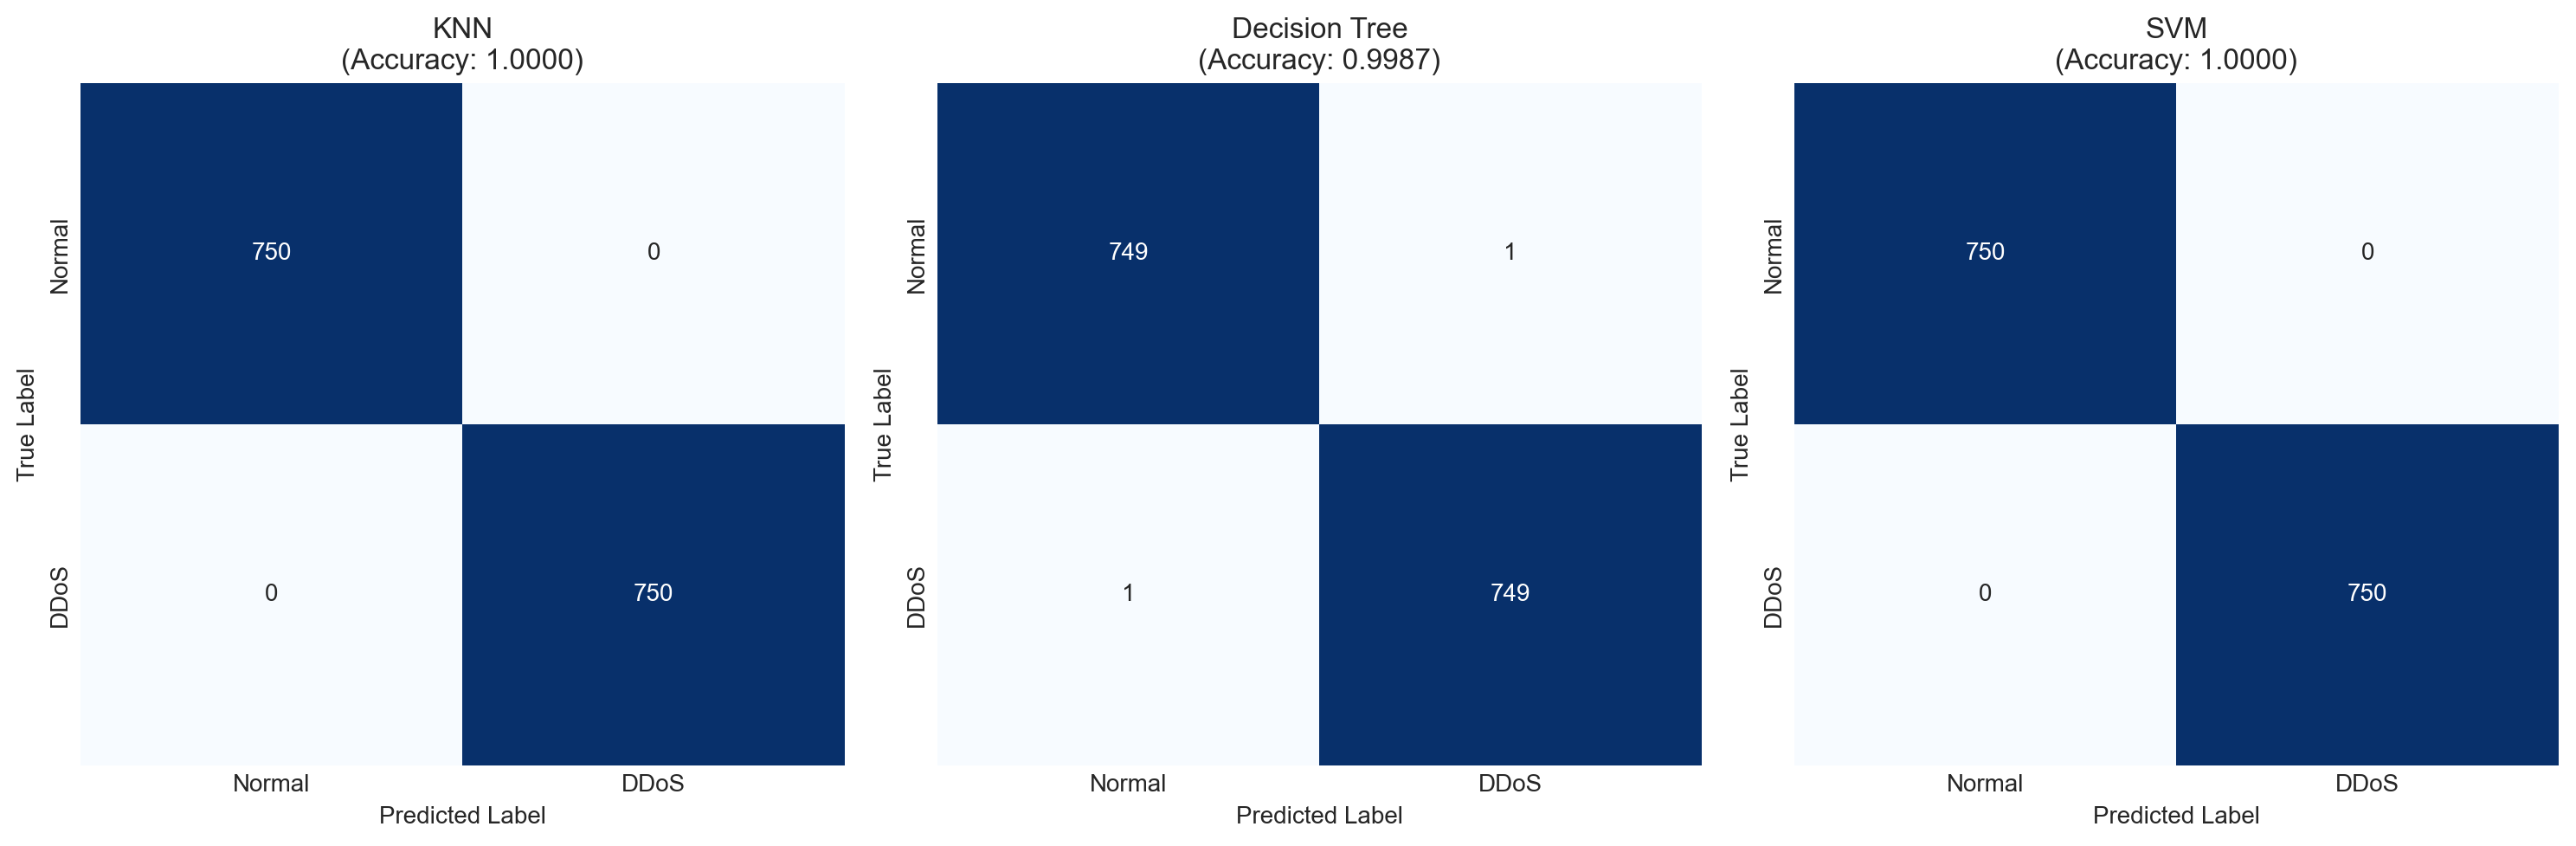

In [17]:
os.makedirs('../results', exist_ok=True)
evaluator.plot_confusion_matrices(save_path='../results/confusion_matrices.png')

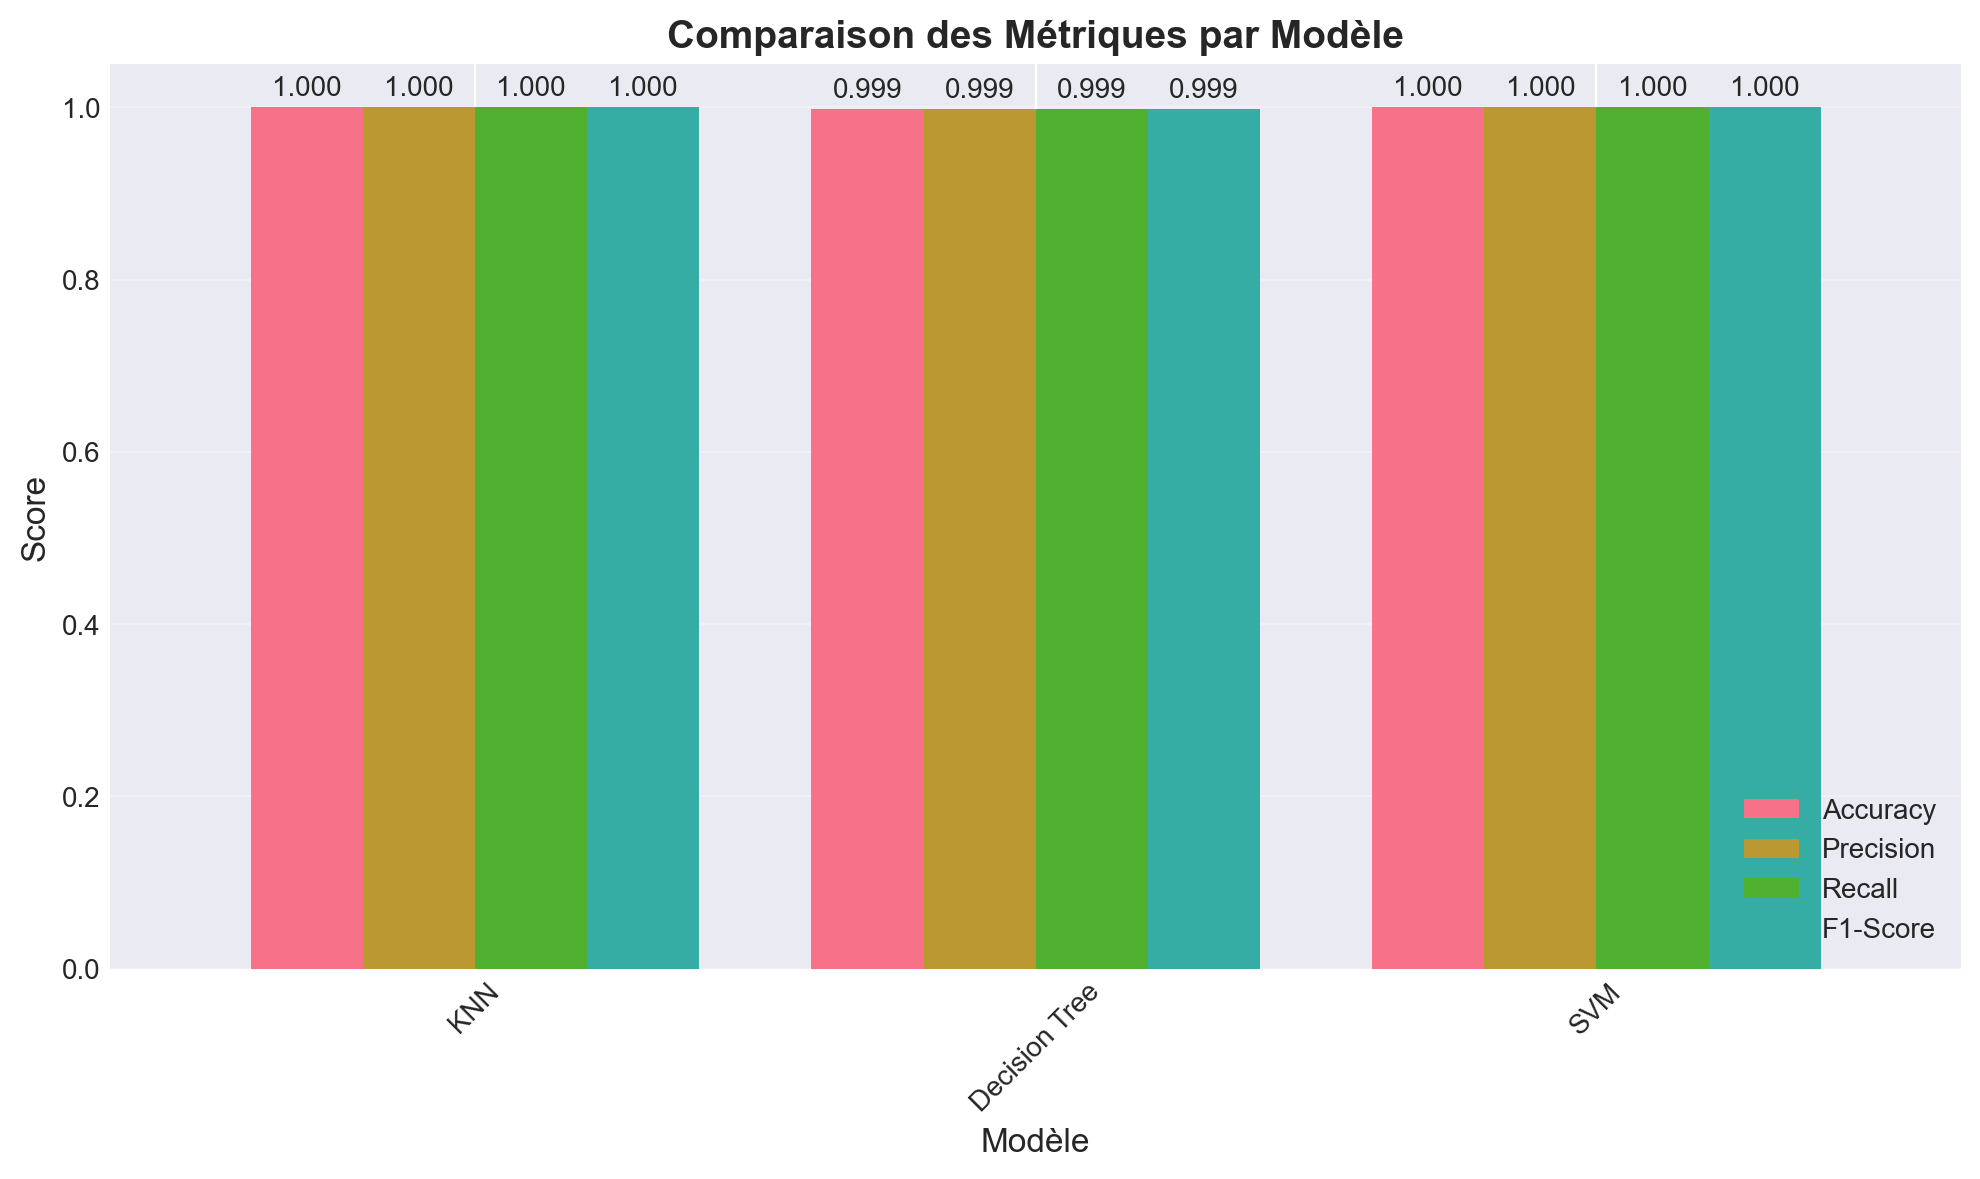

In [18]:
evaluator.plot_metrics_comparison(save_path='../results/metrics_comparison.png')

In [19]:
print(f"\n⚡ PREDICTION TIMING (IoT critical)\n{'='*50}\n")
for m in ['KNN', 'Decision Tree', 'SVM']:
    t = trainer.predict_with_timing(m, X_test)
    ms = (trainer.prediction_times[m] / len(X_test)) * 1000
    print(f"{m:20s}: {trainer.prediction_times[m]:.4f}s ({ms:.3f}ms/sample)")


⚡ PREDICTION TIMING (IoT critical)

KNN                 : 0.1589s (0.106ms/sample)
Decision Tree       : 0.0000s (0.000ms/sample)
SVM                 : 0.0020s (0.001ms/sample)


INSIGHTS

In [20]:
print(f"\n{'='*60}\n🎯 IoT DEPLOYMENT\n{'='*60}\n")
cdict = comparison.to_dict(orient='index')
best = max(cdict, key=lambda x: cdict[x]['F1-Score'])

print(f"Best Model: {best}")
print(f"  F1: {cdict[best]['F1-Score']:.4f}")
print(f"  Accuracy: {cdict[best]['Accuracy']:.4f}")
print(f"  Recall: {evaluator.results[best]['recall']:.4f}")

print(f"\nCharacteristics:")
for m, c in [('KNN', 'Fast | High memory'), ('DT', 'Interpretable | No standardization'), ('SVM', 'Accurate | Slower')]:
    print(f"  {m:5s}: {c}")


🎯 IoT DEPLOYMENT

Best Model: KNN
  F1: 1.0000
  Accuracy: 1.0000
  Recall: 1.0000

Characteristics:
  KNN  : Fast | High memory
  DT   : Interpretable | No standardization
  SVM  : Accurate | Slower


In [21]:
print(f"\n💾 Saving results...")
evaluator.export_results('../results/model_comparison.xlsx')
print(f"✓ Results saved!")


💾 Saving results...
✓ Résultats exportés: ../results/model_comparison.xlsx
✓ Results saved!


In [22]:
print(f"""
{'='*60}
✅ PROJECT COMPLETE
{'='*60}

✓ Code modules (src/)
✓ Dataset (data/)
✓ 3 Models trained
✓ Evaluation complete
✓ Results exported (results/)
""")


✅ PROJECT COMPLETE

✓ Code modules (src/)
✓ Dataset (data/)
✓ 3 Models trained
✓ Evaluation complete
✓ Results exported (results/)



In [23]:
# Imports
import sys
import os
sys.path.insert(0, '../src')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Imports locaux
from preprocessing import DataPreprocessor
from models import ModelTrainer
from evaluation import ModelEvaluator
from utils import (
    download_ton_iot_dataset, create_sample_dataset,
    analyze_class_distribution, analyze_features,
    print_project_structure, get_system_info
)

# Configuration
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

print("✓ Imports réussis")

✓ Imports réussis


In [24]:
# Infos système
get_system_info()
print_project_structure()


🖥️  INFORMATIONS SYSTÈME
Python:      3.11.9
Platform:    Windows
Scikit-learn: 1.3.0


    📁 DDoS_Detection_Project/
    ├── 📂 data/                    # Données brutes
    ├── 📂 src/                     # Code source
    │   ├── preprocessing.py        # Prétraitement
    │   ├── models.py              # Modèles ML
    │   ├── evaluation.py          # Évaluation
    │   └── utils.py               # Utilitaires
    ├── 📂 notebooks/              # Jupyter notebooks
    │   └── DDoS_Detection_4IIR.ipynb
    ├── 📂 results/                # Résultats & figures
    ├── requirements.txt           # Dépendances Python
    └── README.md                  # Documentation
    


CHARGEMENT & EXPLORATION DES DONNÉES

In [25]:
# Charger les données
preprocessor = DataPreprocessor()

# Utiliser le dataset sample (créé automatiquement)
data_path = '../data/ton_iot_sample.csv'

df = preprocessor.load_data(data_path)
print(f"✓ Dataset chargé avec succès: {df.shape}")

✓ Données chargées: (10000, 26)
✓ Dataset chargé avec succès: (10000, 26)


In [26]:
# Charger les données
preprocessor = DataPreprocessor()

# Essayer de charger le dataset TON_IoT
# MODIFIEZ le chemin selon votre dataset
data_path = '../data/ton_iot_data.csv'  # À adapter

try:
    df = preprocessor.load_data(data_path)
except FileNotFoundError:
    print(f"⚠️  {data_path} non trouvé")
    print("\n📊 Création d'un dataset sample pour démonstration...")
    df = create_sample_dataset(n_samples=10000)
    data_path = '../data/sample_data.csv'
    os.makedirs(os.path.dirname(data_path), exist_ok=True)
    df.to_csv(data_path, index=False)
    print(f"✓ Dataset sauvegardé: {data_path}")

⚠️  ../data/ton_iot_data.csv non trouvé

📊 Création d'un dataset sample pour démonstration...
📊 Création d'un dataset sample (10000 samples)...
✓ Dataset créé: (10000, 21)
✓ Dataset sauvegardé: ../data/sample_data.csv


In [27]:
# Exploration
print("\n📊 STATISTIQUES GÉNÉRALES:")
print(f"Shape: {df.shape}")
print(f"\nColonnes:\n{df.columns.tolist()}")
print(f"\nTypes de données:\n{df.dtypes}")
print(f"\nValeurs manquantes:\n{df.isnull().sum()}")


📊 STATISTIQUES GÉNÉRALES:
Shape: (10000, 21)

Colonnes:
['feature_0', 'feature_1', 'feature_2', 'feature_3', 'feature_4', 'feature_5', 'feature_6', 'feature_7', 'feature_8', 'feature_9', 'feature_10', 'feature_11', 'feature_12', 'feature_13', 'feature_14', 'feature_15', 'feature_16', 'feature_17', 'feature_18', 'feature_19', 'attack']

Types de données:
feature_0     float64
feature_1     float64
feature_2     float64
feature_3     float64
feature_4     float64
feature_5     float64
feature_6     float64
feature_7     float64
feature_8     float64
feature_9     float64
feature_10    float64
feature_11    float64
feature_12    float64
feature_13    float64
feature_14    float64
feature_15    float64
feature_16    float64
feature_17    float64
feature_18    float64
feature_19    float64
attack          int32
dtype: object

Valeurs manquantes:
feature_0     0
feature_1     0
feature_2     0
feature_3     0
feature_4     0
feature_5     0
feature_6     0
feature_7     0
feature_8     0
fe

In [28]:
# Identifier la colonne target
# Adapter selon votre dataset (cherchez 'attack', 'label', 'normal', etc.)
possible_targets = ['attack', 'label', 'class', 'target', 'type', 'normal']
target_col = None

for col in df.columns:
    if any(target in col.lower() for target in possible_targets):
        target_col = col
        break

if target_col is None:
    # Par défaut: dernière colonne
    target_col = df.columns[-1]

print(f"✓ Colonne target identifiée: {target_col}")
print(f"\nValeurs uniques: {df[target_col].unique()}")
print(f"\nDistribution:")
print(df[target_col].value_counts())

✓ Colonne target identifiée: attack

Valeurs uniques: [1 0]

Distribution:
attack
1    5000
0    5000
Name: count, dtype: int64


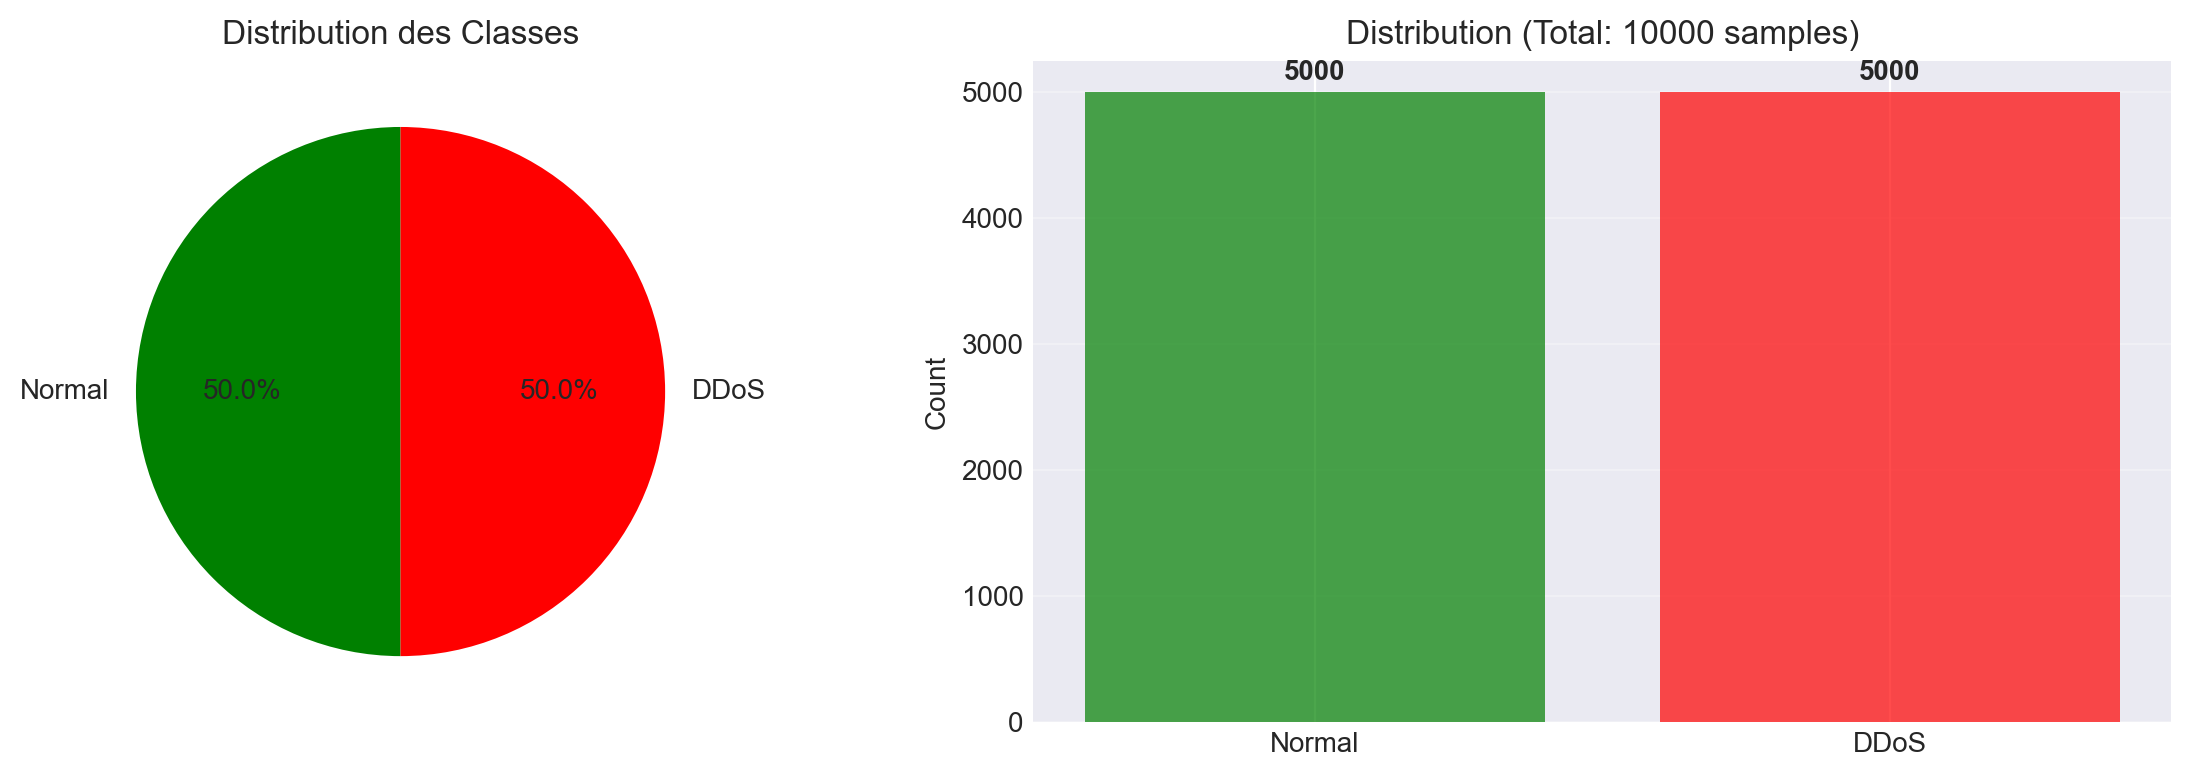

In [29]:
# Visualiser la distribution des classes
analyze_class_distribution(df[target_col].values)

PRÉTRAITEMENT

In [30]:
# Identifier les colonnes catégorielles
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()
if target_col in categorical_cols:
    categorical_cols.remove(target_col)

print(f"Colonnes catégorielles: {categorical_cols}")

# Prétraitement complet
X_train, X_val, X_test, y_train, y_val, y_test = preprocessor.preprocess(
    df, 
    target_col=target_col,
    categorical_cols=categorical_cols if categorical_cols else None
)

print("\n✓ Prétraitement terminé")

Colonnes catégorielles: []

🔧 PRÉTRAITEMENT
✓ Pas de valeurs manquantes
✓ Pas de colonnes catégorielles

⚠️  Distribution des classes:
  Classe 0: 5000 (50.0%)
  Classe 1: 5000 (50.0%)
✓ Split stratifié:
  Train: 7000 samples
  Val:   1500 samples
  Test:  1500 samples
✓ Données standardisées (z-score)

✓ Prétraitement terminé


In [31]:
# Vérifier les formes
print(f"\n✓ Formes après prétraitement:")
print(f"  X_train: {X_train.shape}")
print(f"  X_val:   {X_val.shape}")
print(f"  X_test:  {X_test.shape}")
print(f"\n  y_train unique: {np.unique(y_train, return_counts=True)}")
print(f"  y_test unique:  {np.unique(y_test, return_counts=True)}")


✓ Formes après prétraitement:
  X_train: (7000, 20)
  X_val:   (1500, 20)
  X_test:  (1500, 20)

  y_train unique: (array([0, 1]), array([3500, 3500], dtype=int64))
  y_test unique:  (array([0, 1]), array([750, 750], dtype=int64))


ENTRAÎNEMENT DES MODÈLES

In [32]:
# Initialiser le trainer
trainer = ModelTrainer()

print("🚀 ENTRAÎNEMENT DES MODÈLES")
print(f"{'='*60}")

🚀 ENTRAÎNEMENT DES MODÈLES


In [33]:
# 1. KNN
model_knn = trainer.train_knn(X_train, y_train, X_val, y_val, k_values=[3, 5, 7, 9, 11, 15, 21])


🟦 K-NEAREST NEIGHBORS (KNN)
Test k values: [3, 5, 7, 9, 11, 15, 21]
  k= 3 -> Val Accuracy: 1.0000
  k= 5 -> Val Accuracy: 1.0000
  k= 7 -> Val Accuracy: 1.0000
  k= 9 -> Val Accuracy: 1.0000
  k=11 -> Val Accuracy: 1.0000
  k=15 -> Val Accuracy: 1.0000
  k=21 -> Val Accuracy: 1.0000

✓ Meilleur k: 3
✓ Temps d'entraînement: 0.0010s


In [34]:
# 2. Decision Tree
model_dt = trainer.train_decision_tree(X_train, y_train, X_val, y_val)


🟩 DECISION TREE
✓ Meilleurs paramètres: {'max_depth': 5, 'min_samples_split': 2, 'min_samples_leaf': 1}
✓ Temps d'entraînement: 0.1980s


In [35]:
# 3. SVM
model_svm = trainer.train_svm(X_train, y_train, X_val, y_val)


🟪 SUPPORT VECTOR MACHINE (SVM)
Test kernels: ['linear', 'rbf', 'poly']
Test C values: [0.1, 1, 10, 100]
  kernel=linear, C=   0.1 -> Val Accuracy: 1.0000
  kernel=linear, C=   1.0 -> Val Accuracy: 1.0000
  kernel=linear, C=  10.0 -> Val Accuracy: 1.0000
  kernel=linear, C= 100.0 -> Val Accuracy: 1.0000
  kernel=rbf  , C=   0.1 -> Val Accuracy: 1.0000
  kernel=rbf  , C=   1.0 -> Val Accuracy: 1.0000
  kernel=rbf  , C=  10.0 -> Val Accuracy: 1.0000
  kernel=rbf  , C= 100.0 -> Val Accuracy: 1.0000
  kernel=poly , C=   0.1 -> Val Accuracy: 1.0000
  kernel=poly , C=   1.0 -> Val Accuracy: 1.0000
  kernel=poly , C=  10.0 -> Val Accuracy: 1.0000
  kernel=poly , C= 100.0 -> Val Accuracy: 1.0000

✓ Meilleur kernel: linear, C: 0.1
✓ Temps d'entraînement: 0.0644s


In [36]:
# Résumé de l'entraînement
summary = trainer.get_summary()
print(f"\n{'='*60}")
print("📈 RÉSUMÉ DE L'ENTRAÎNEMENT")
print(f"{'='*60}")

print(f"\n⏱️  TEMPS D'ENTRAÎNEMENT (secondes):")
for model, time_val in summary['Training Times'].items():
    print(f"  {model:20s}: {time_val:8.4f}s")

print(f"\n🎯 MEILLEURS PARAMÈTRES:")
for model, params in summary['Best Parameters'].items():
    print(f"  {model}:")
    for param, value in params.items():
        print(f"    {param}: {value}")


📈 RÉSUMÉ DE L'ENTRAÎNEMENT

⏱️  TEMPS D'ENTRAÎNEMENT (secondes):
  KNN                 :   0.0010s
  Decision Tree       :   0.1980s
  SVM                 :   0.0644s

🎯 MEILLEURS PARAMÈTRES:
  KNN:
    n_neighbors: 3
  Decision Tree:
    max_depth: 5
    min_samples_split: 2
    min_samples_leaf: 1
  SVM:
    kernel: linear
    C: 0.1


 ÉVALUATION & COMPARAISON

In [37]:
# Initialiser l'évaluateur
evaluator = ModelEvaluator()

# Évaluer chaque modèle
result_knn = evaluator.evaluate_model('KNN', model_knn, X_test, y_test, X_val, y_val)
result_dt = evaluator.evaluate_model('Decision Tree', model_dt, X_test, y_test, X_val, y_val)
result_svm = evaluator.evaluate_model('SVM', model_svm, X_test, y_test, X_val, y_val)


ÉVALUATION: KNN

📊 MÉTRIQUES (Test Set):
  Accuracy:  1.0000
  Precision: 1.0000
  Recall:    1.0000
  F1-Score:  1.0000
  ROC-AUC:   1.0000

📋 RAPPORT DÉTAILLÉ:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       750
           1       1.00      1.00      1.00       750

    accuracy                           1.00      1500
   macro avg       1.00      1.00      1.00      1500
weighted avg       1.00      1.00      1.00      1500


🔍 MATRICE DE CONFUSION:
  TN:   750  FP:     0
  FN:     0  TP:   750

🔄 VALIDATION SET:
  Accuracy: 1.0000

ÉVALUATION: Decision Tree

📊 MÉTRIQUES (Test Set):
  Accuracy:  0.9987
  Precision: 0.9973
  Recall:    1.0000
  F1-Score:  0.9987
  ROC-AUC:   0.9987

📋 RAPPORT DÉTAILLÉ:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       750
           1       1.00      1.00      1.00       750

    accuracy                           1.00      1500
   macro a

In [38]:
# Comparaison des modèles
comparison = evaluator.compare_models()


COMPARAISON DES MODÈLES

               Accuracy  Precision  Recall  F1-Score
KNN              1.0000     1.0000     1.0    1.0000
Decision Tree    0.9987     0.9973     1.0    0.9987
SVM              1.0000     1.0000     1.0    1.0000

🏆 MEILLEUR MODÈLE PAR MÉTRIQUE:
  Accuracy  : KNN                  (1.0000)
  Precision : KNN                  (1.0000)
  Recall    : KNN                  (1.0000)
  F1-Score  : KNN                  (1.0000)


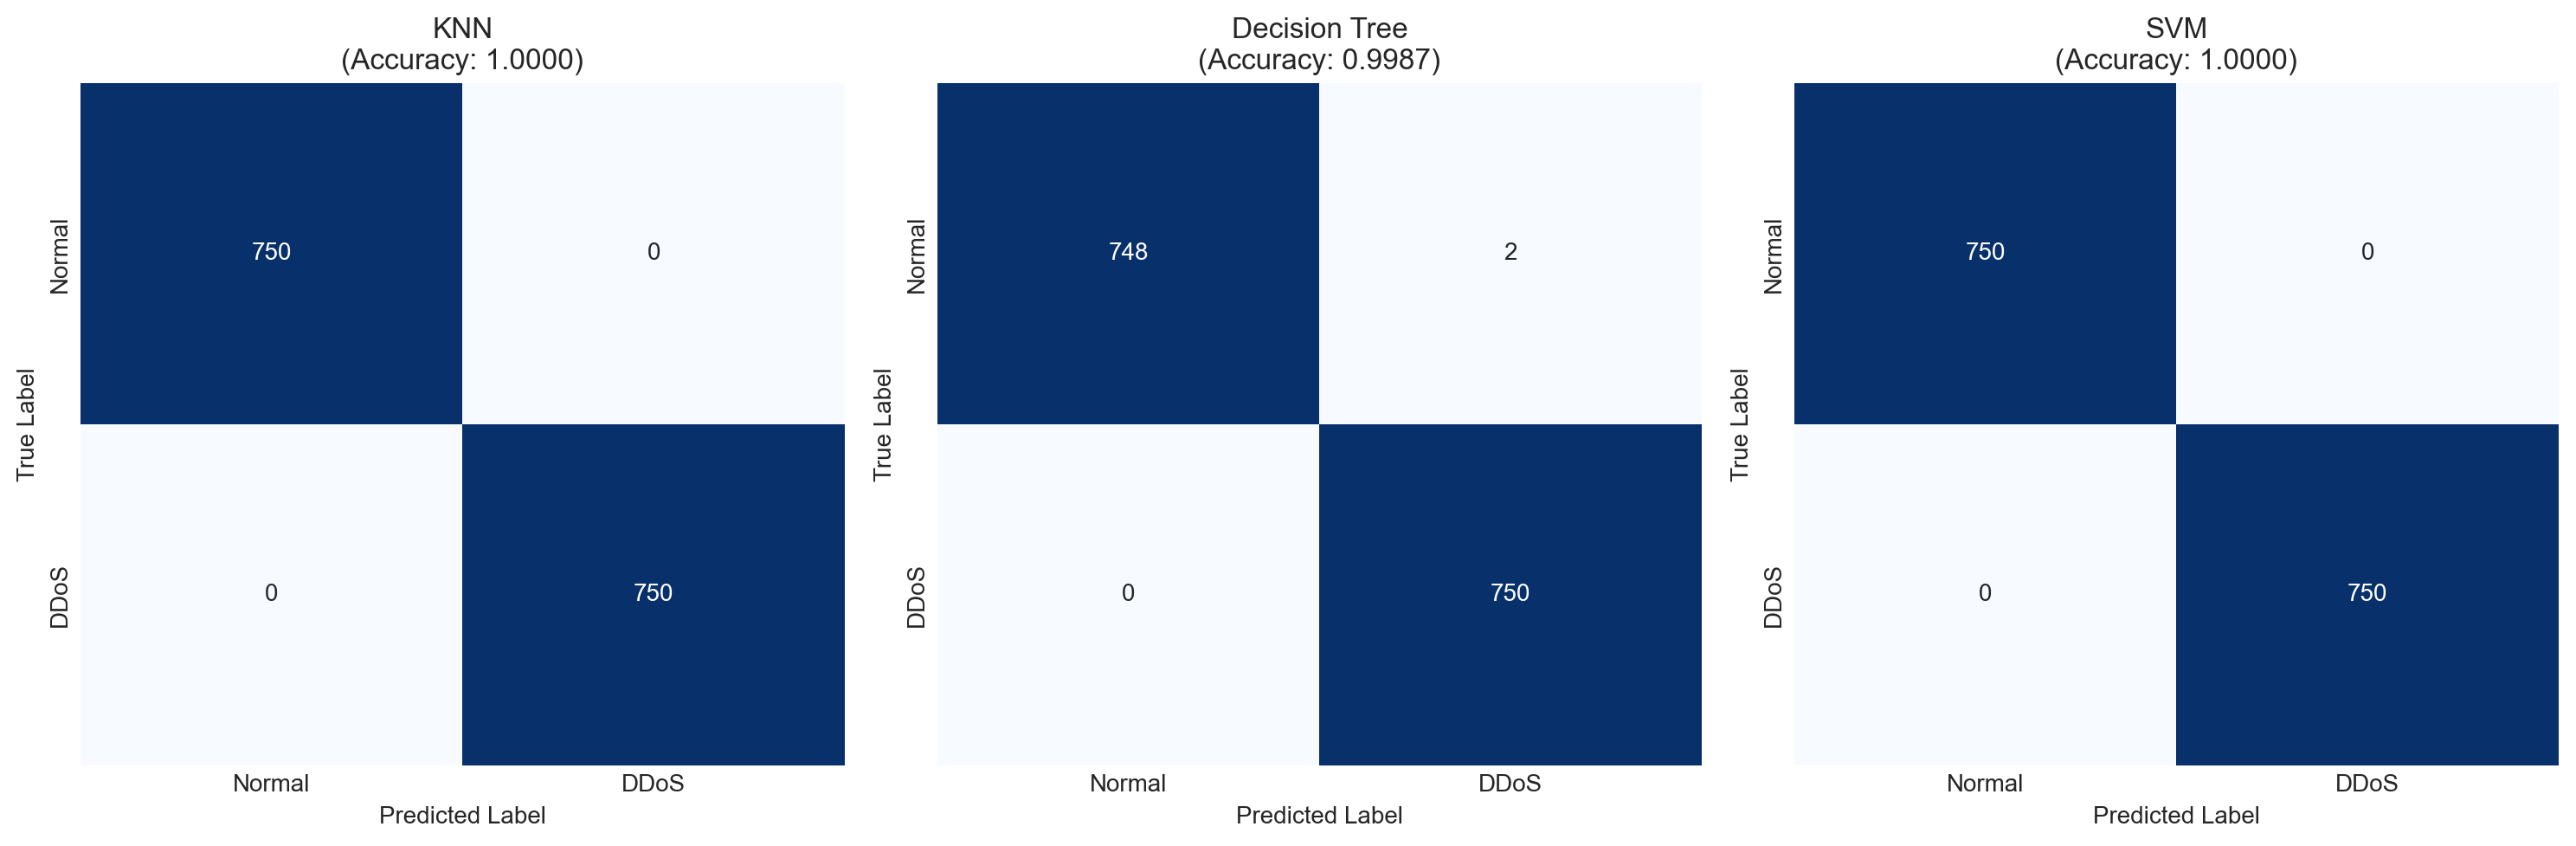

In [39]:
# Afficher les matrices de confusion
evaluator.plot_confusion_matrices(save_path='../results/confusion_matrices.png')

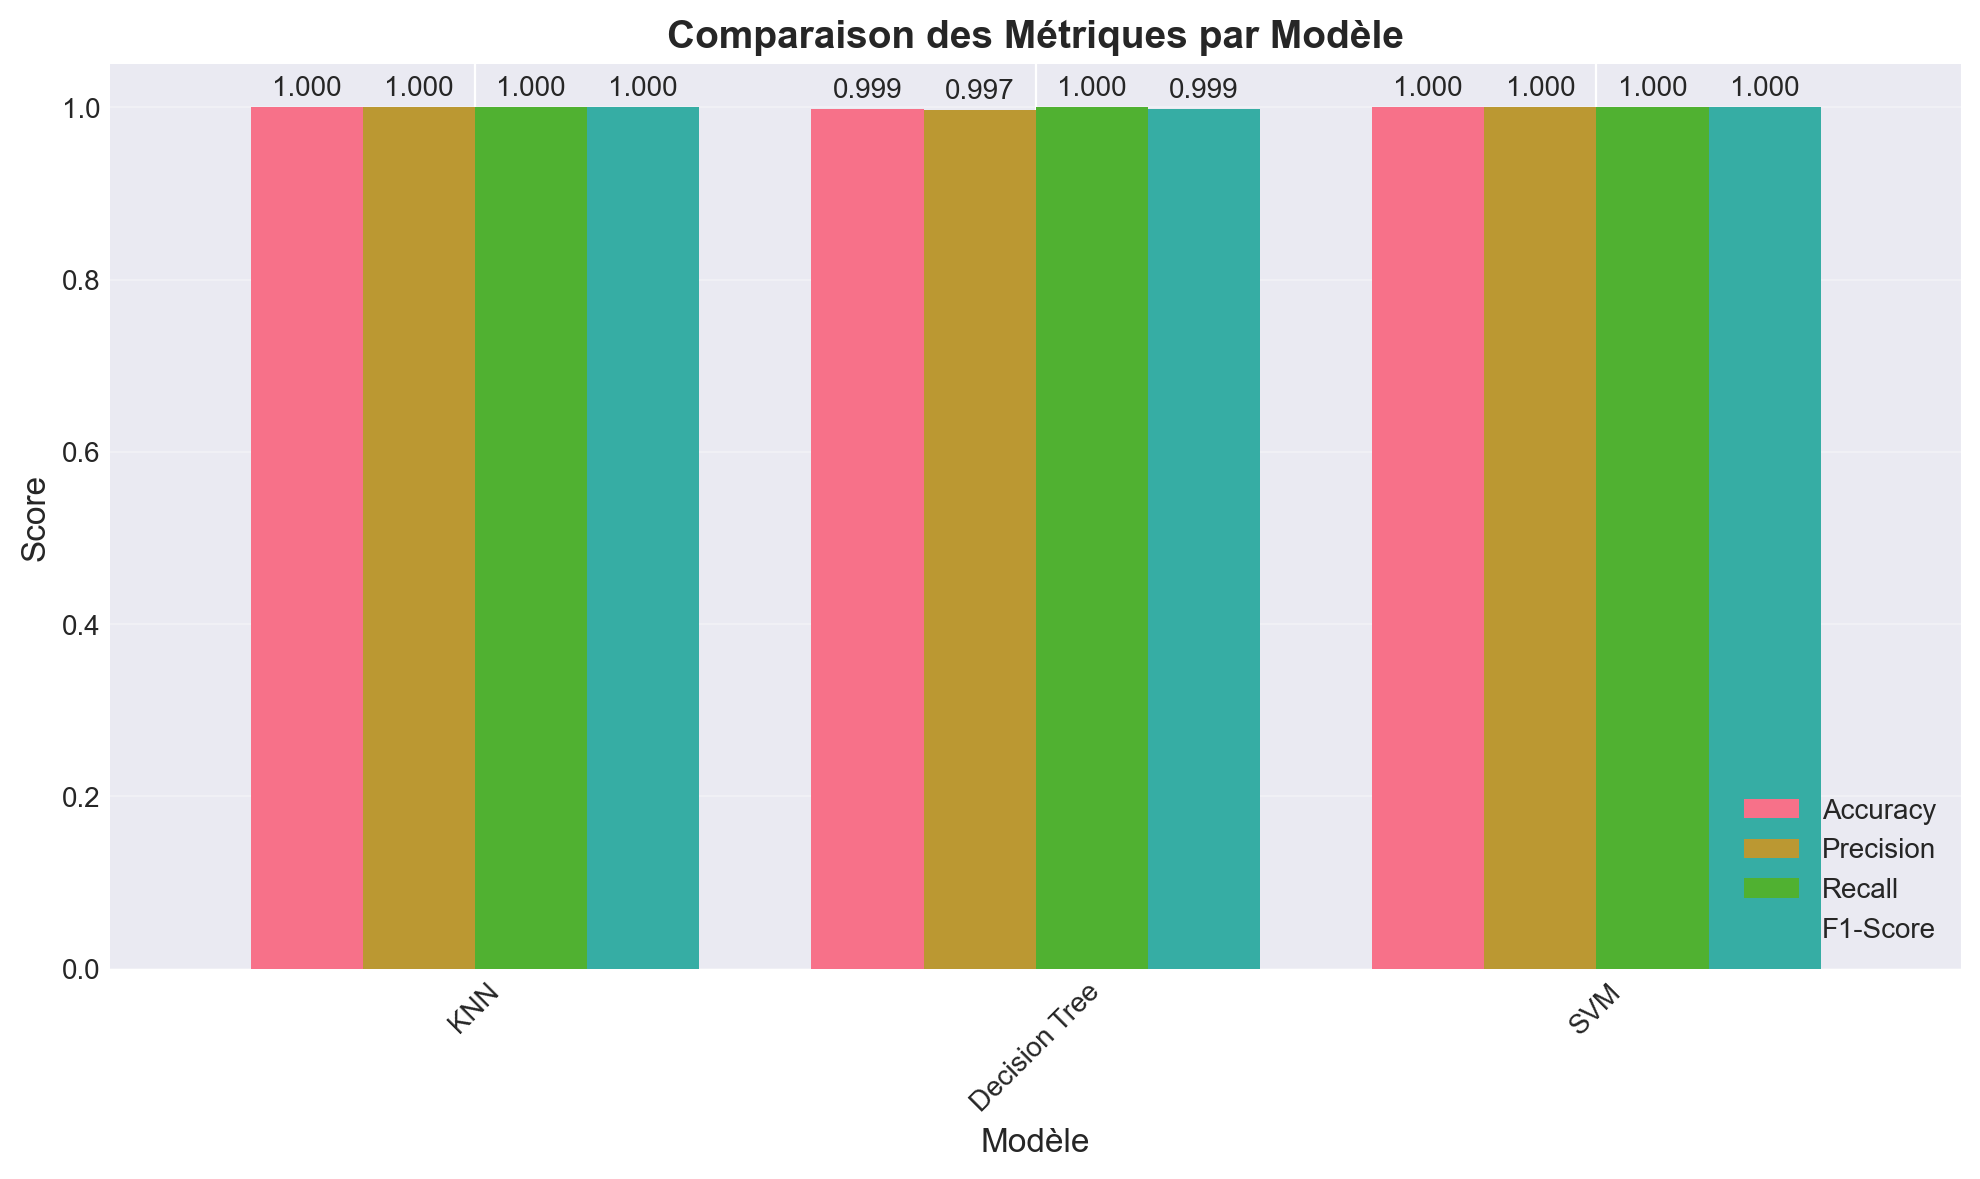

In [40]:
# Comparer les métriques
evaluator.plot_metrics_comparison(save_path='../results/metrics_comparison.png')


📊 COURBES ROC



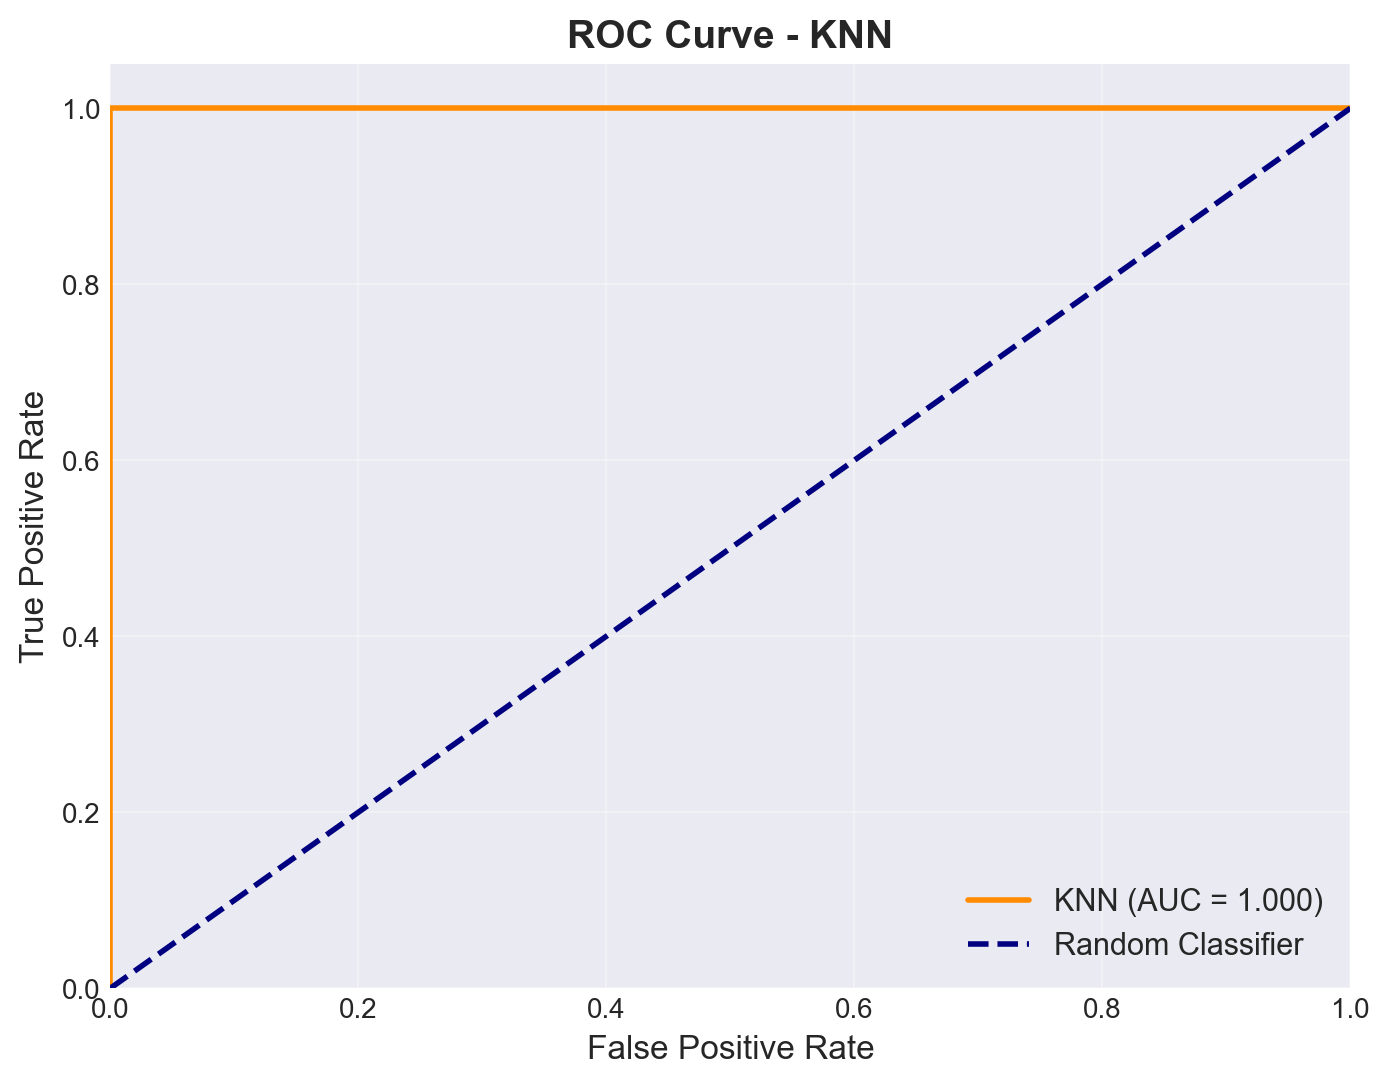

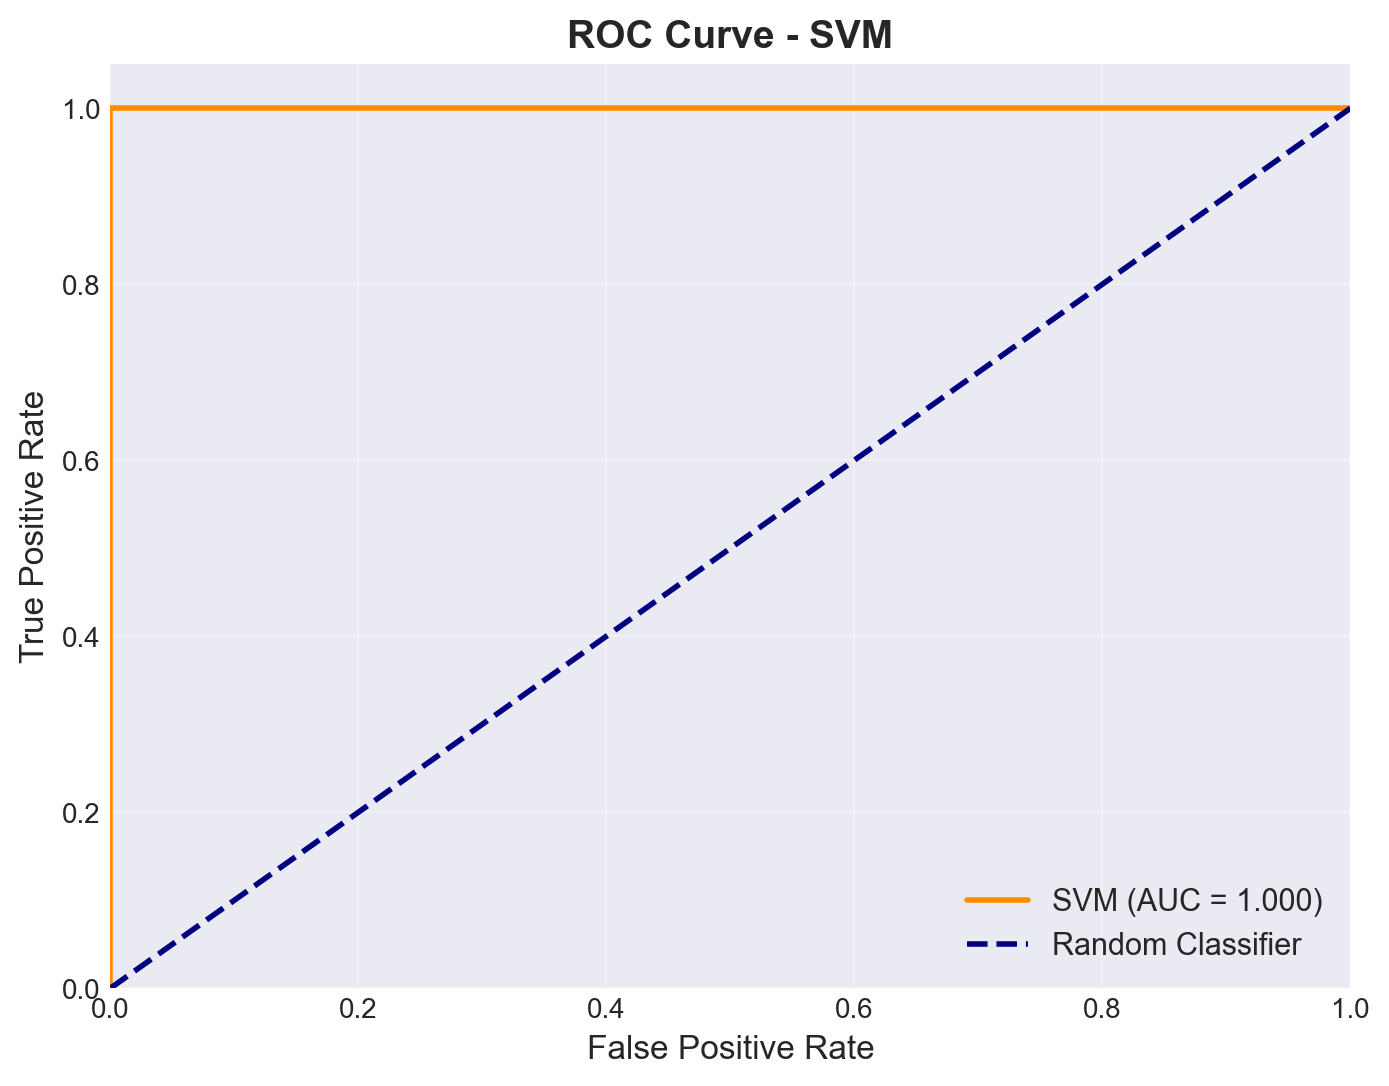

In [41]:
# Courbes ROC (si disponibles)
print("\n📊 COURBES ROC")
print(f"{'='*60}\n")

for model_name, model in [('KNN', model_knn), ('SVM', model_svm)]:
    try:
        evaluator.plot_roc_curves(model, model_name, X_test, y_test, 
                                 save_path=f'../results/roc_{model_name.lower()}.png')
    except Exception as e:
        print(f"⚠️  {model_name} ROC non disponible: {e}")

 ANALYSE & INTERPRÉTATION

In [42]:
# Temps de prédiction
print("\n⚡ TEMPS DE PRÉDICTION (IMPORTANT POUR IoT)")
print(f"{'='*60}\n")

for model_name in ['KNN', 'Decision Tree', 'SVM']:
    pred_time = trainer.predict_with_timing(model_name, X_test)
    ms_per_sample = (trainer.prediction_times[model_name] / len(X_test)) * 1000
    print(f"{model_name:20s}: {trainer.prediction_times[model_name]:8.4f}s ({ms_per_sample:6.3f}ms/sample)")

print(f"\n💡 Pour un appareil IoT avec CPU limité:")
print(f"   - KNN & SVM sont rapides")
print(f"   - Decision Tree offre le meilleur compromis")


⚡ TEMPS DE PRÉDICTION (IMPORTANT POUR IoT)

KNN                 :   0.0700s ( 0.047ms/sample)
Decision Tree       :   0.0020s ( 0.001ms/sample)
SVM                 :   0.0020s ( 0.001ms/sample)

💡 Pour un appareil IoT avec CPU limité:
   - KNN & SVM sont rapides
   - Decision Tree offre le meilleur compromis


In [43]:
# Analyse de robustesse au déséquilibre
print("\n🎯 ROBUSTESSE AU DÉSÉQUILIBRE")
print(f"{'='*60}\n")

for model_name in ['KNN', 'Decision Tree', 'SVM']:
    recall = evaluator.results[model_name]['recall']
    precision = evaluator.results[model_name]['precision']
    f1 = evaluator.results[model_name]['f1']
    
    print(f"{model_name}:")
    print(f"  Recall (capacité à détecter les attaques):  {recall:.4f}")
    print(f"  Precision (faux positifs):                   {precision:.4f}")
    print(f"  F1-Score (équilibre):                        {f1:.4f}")
    
    if recall > 0.95:
        print(f"  ✓ BON: Détecte bien les attaques")
    elif recall > 0.85:
        print(f"  ⚠️  MOYEN: Manque certaines attaques")
    else:
        print(f"  ❌ FAIBLE: Détection insuffisante")
    print()


🎯 ROBUSTESSE AU DÉSÉQUILIBRE

KNN:
  Recall (capacité à détecter les attaques):  1.0000
  Precision (faux positifs):                   1.0000
  F1-Score (équilibre):                        1.0000
  ✓ BON: Détecte bien les attaques

Decision Tree:
  Recall (capacité à détecter les attaques):  1.0000
  Precision (faux positifs):                   0.9973
  F1-Score (équilibre):                        0.9987
  ✓ BON: Détecte bien les attaques

SVM:
  Recall (capacité à détecter les attaques):  1.0000
  Precision (faux positifs):                   1.0000
  F1-Score (équilibre):                        1.0000
  ✓ BON: Détecte bien les attaques



 RECOMMANDATIONS FINALES

In [44]:
print("\n" + "="*60)
print("🏆 RECOMMANDATIONS POUR LA DÉTECTION DDoS EN IoT")
print("="*60)

comparison_dict = comparison.to_dict(orient='index')
best_model = max(comparison_dict, key=lambda x: comparison_dict[x]['F1-Score'])

print(f"\n✓ MEILLEUR MODÈLE GLOBAL: {best_model}")
print(f"  F1-Score: {comparison_dict[best_model]['F1-Score']:.4f}")
print(f"  Accuracy: {comparison_dict[best_model]['Accuracy']:.4f}")
print(f"\nCRITÈRES IoT:")
print(f"  1️⃣  Rappel (detection attacks):   {evaluator.results[best_model]['recall']:.4f}")
print(f"  2️⃣  Temps de prédiction:         {trainer.prediction_times[best_model]:.4f}s")
print(f"  3️⃣  Facilité de déploiement:     ")
if best_model == 'Decision Tree':
    print(f"      → Interprétable, pas de normalisation")
elif best_model == 'KNN':
    print(f"      → Simple, mais consomme mémoire")
else:
    print(f"      → Performant, nécessite standardisation")

print(f"\n💾 SAUVEGARDE DES RÉSULTATS...")
os.makedirs('../results', exist_ok=True)
evaluator.export_results('../results/model_comparison.xlsx')
print(f"✓ Résultats sauvegardés dans 'results/'")


🏆 RECOMMANDATIONS POUR LA DÉTECTION DDoS EN IoT

✓ MEILLEUR MODÈLE GLOBAL: KNN
  F1-Score: 1.0000
  Accuracy: 1.0000

CRITÈRES IoT:
  1️⃣  Rappel (detection attacks):   1.0000
  2️⃣  Temps de prédiction:         0.0700s
  3️⃣  Facilité de déploiement:     
      → Simple, mais consomme mémoire

💾 SAUVEGARDE DES RÉSULTATS...
✓ Résultats exportés: ../results/model_comparison.xlsx
✓ Résultats sauvegardés dans 'results/'
